# Committor Model: 1D Low-Friction Langevin Dynamics, 10× Smaller Time Step

Same system and fit as `base_documented_1d_langevin.ipynb`, on a new MD with a 10× smaller integration time step, to test whether the fit's convergence (and its seed dependence) is sensitive to the integrator.

**Data:** `md_istarwell2_dt5e-4_10M/md_path.npy`: 10M rows, written every 10 steps of dt = 0.0005 (100M steps), so one row per 0.005 time units, as in the original run `md_istarwell2_100M` (one row per step of dt = 0.005). Columns λ and v. Same start (λ = −0.355), seed 1, friction γ = 1, kT = 1, m = 1, toytis BBK Langevin integrator (`notebooks/md_run.py`).

**Potential:** `CosWellWalls`, a well of depth 1.2 kT on [−0.25, 0.25], flanked by 0.15 kT bumps and flat regions, with harmonic walls (k = 100) beyond ±0.45.

**Boundaries:** `λ <= -0.35` (A) and `λ >= 0.35` (B), checked on the saved rows (every 0.005 time units in both runs).

**Section 2b** compares the committor taken directly from the MD outcomes (no fit) of both runs with each other and with the brute-force reference q(λ, v), which was computed with the dt = 0.005 integrator. A difference between the runs there means the integrator changes the dynamics; the fits are then compared against each run's own MD-outcome committor.

## 1. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

# Plot styling
plt.rc('font', size=10)
plt.rc('axes', titlesize=14)
plt.rc('axes', labelsize=14)
plt.rc('xtick', labelsize=12)
plt.rc('ytick', labelsize=12)
plt.rc('legend', fontsize=12)

# Custom optimal-RC / committor package
import sys
import os
sys.path.insert(0, os.path.abspath('../optimalrcs-cupy'))   # relative to this notebook's folder (examples/)
import optimalrcs, metrics, plots

## 2. Data Loading

Loads the first `n_frames` frames (5M frames contain about 8000 A↔B transitions). The velocity `v` is only used to check the result in section 6, not in training.

In [4]:
SIMS = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations'   # adjust on another machine
SRC = f'{SIMS}/md_istarwell2_dt5e-4_10M'   # dt = 0.0005, one row per 10 steps
SRC_OLD = f'{SIMS}/md_istarwell2_100M'      # dt = 0.005, one row per step (section 2b only)
n_frames = 7_000_000

data = np.load(f'{SRC}/md_path.npy', mmap_mode='r')[:n_frames]
lam, v = np.array(data[:, 0]), np.array(data[:, 1])
lambda_a, lambda_b = -0.35, 0.35
dt = 0.005                         # time per saved row (10 steps of 0.0005)
print(f'Frames: {len(lam)}')

Frames: 7000000


## 2b. Committor from the MD Outcomes (No Fit)

For every frame outside A and B: does the trajectory reach B before A? The mean of that outcome per (λ, v) bin is the committor, estimated directly from the data. It is computed on `n_frames` rows of this run (dt = 0.0005) and of the original run (dt = 0.005), which cover the same physical time, and compared with the brute-force reference q(λ, v) (shooting with the dt = 0.005 integrator, 29 × 29 grid).

The noise of each map is estimated from its two halves (first and second half of the rows, which are independent): noise = RMS(half 1 − half 2) / 2. If the two runs differ by no more than their combined noise, the smaller time step does not change the committor.

A->B transitions in 7000000 rows: dt = 0.0005: 5863, dt = 0.005: 5855
noise per bin (from the two halves): dt = 0.0005: 0.0087, dt = 0.005: 0.0115, combined 0.0144
RMS per bin: new - old 0.0128 | new - reference 0.0129 | old - reference 0.0118
mean per bin: new - old +0.0013 | new - reference +0.0021 | old - reference +0.0009


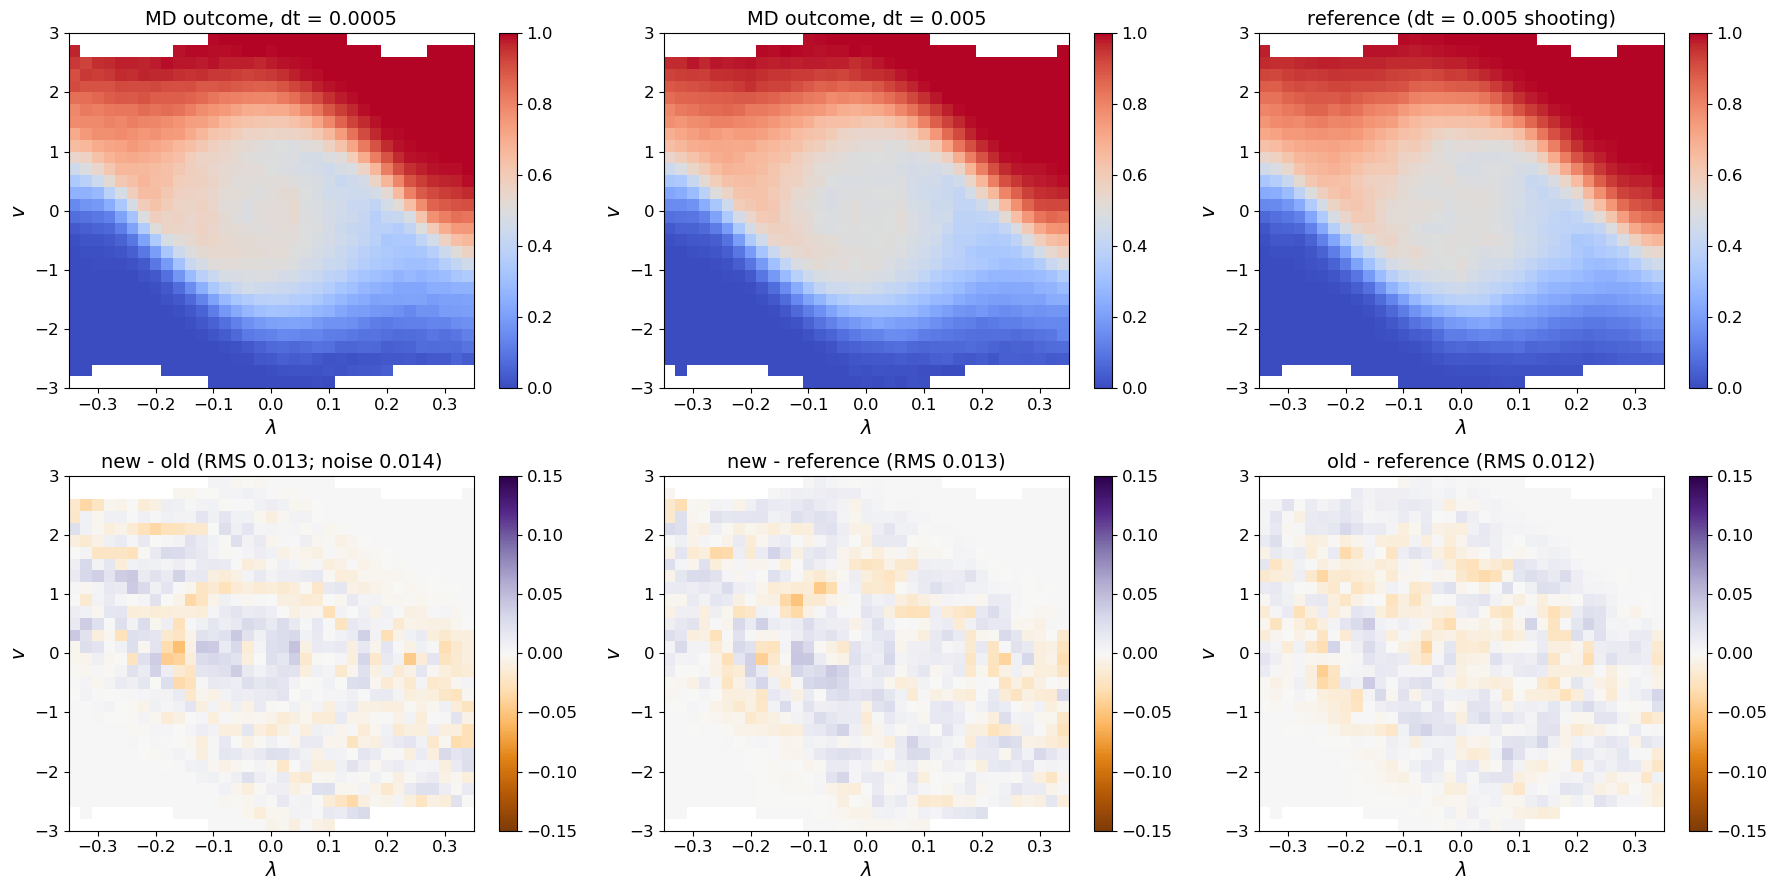

In [5]:
import os
from scipy.interpolate import RegularGridInterpolator

def md_outcome(x):
    # 1 if the next A/B row is in B, 0 if in A, nan if neither is reached before the data end
    A, B = x <= lambda_a, x >= lambda_b
    n = len(x)
    idx = np.where(A | B, np.arange(n), n)
    nxt = np.minimum.accumulate(idx[::-1])[::-1]
    out = np.where(nxt < n, B[np.minimum(nxt, n - 1)].astype(float), np.nan)
    return out, ~A & ~B & np.isfinite(out)

def n_ab(x):
    s = np.where(x <= lambda_a, 0, np.where(x >= lambda_b, 1, -1))
    s = s[s >= 0]
    return int(np.sum(np.diff(s) == 1))

old = np.load(f'{SRC_OLD}/md_path.npy', mmap_mode='r')[:n_frames]
lam_old, v_old = np.array(old[:, 0]), np.array(old[:, 1])
out_new, ok_new = md_outcome(lam)
out_old, ok_old = md_outcome(lam_old)
print(f'A->B transitions in {n_frames} rows: dt = 0.0005: {n_ab(lam)}, dt = 0.005: {n_ab(lam_old)}')

ref = np.load('figures/well_check/reference.npz')
f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)
q_ref = lambda x, vv: np.clip(f_ref(np.c_[np.clip(x, ref['xs'][0], ref['xs'][-1]), np.clip(vv, ref['vs'][0], ref['vs'][-1])]), 0, 1)

el, ev = np.linspace(lambda_a, lambda_b, 36), np.linspace(-3, 3, 31)
def bmap(x, vv, val, ok, sel=None, min_n=200):
    m = ok if sel is None else ok & sel
    n = np.histogram2d(x[m], vv[m], [el, ev])[0]
    s = np.histogram2d(x[m], vv[m], [el, ev], weights=val[m])[0]
    return np.where(n > min_n, s / np.maximum(n, 1), np.nan)
half = lambda n: np.arange(n) < n // 2

M_new, M_old = bmap(lam, v, out_new, ok_new), bmap(lam_old, v_old, out_old, ok_old)
R_new = bmap(lam, v, q_ref(lam, v), ok_new)          # reference averaged over the same frames
R_old = bmap(lam_old, v_old, q_ref(lam_old, v_old), ok_old)
noise = lambda x, vv, out, ok: np.sqrt(np.nanmean((bmap(x, vv, out, ok, half(len(x)), 100)
                                                     - bmap(x, vv, out, ok, ~half(len(x)), 100)) ** 2)) / 2
n_new, n_old = noise(lam, v, out_new, ok_new), noise(lam_old, v_old, out_old, ok_old)
rms = lambda a: np.sqrt(np.nanmean(a ** 2))
print(f'noise per bin (from the two halves): dt = 0.0005: {n_new:.4f}, dt = 0.005: {n_old:.4f}, '
      f'combined {np.hypot(n_new, n_old):.4f}')
print(f'RMS per bin: new - old {rms(M_new - M_old):.4f} | new - reference {rms(M_new - R_new):.4f} '
      f'| old - reference {rms(M_old - R_old):.4f}')
print(f'mean per bin: new - old {np.nanmean(M_new - M_old):+.4f} | new - reference {np.nanmean(M_new - R_new):+.4f} '
      f'| old - reference {np.nanmean(M_old - R_old):+.4f}')

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
panels = [(M_new, 'MD outcome, dt = 0.0005', 'coolwarm', 1), (M_old, 'MD outcome, dt = 0.005', 'coolwarm', 1),
          (R_new, 'reference (dt = 0.005 shooting)', 'coolwarm', 1),
          (M_new - M_old, f'new - old (RMS {rms(M_new - M_old):.3f}; noise {np.hypot(n_new, n_old):.3f})', 'PuOr', 0.15),
          (M_new - R_new, f'new - reference (RMS {rms(M_new - R_new):.3f})', 'PuOr', 0.15),
          (M_old - R_old, f'old - reference (RMS {rms(M_old - R_old):.3f})', 'PuOr', 0.15)]
for ax, (Mp, t, cm, lim) in zip(axes.ravel(), panels):
    im = ax.pcolormesh(el, ev, Mp.T, cmap=cm, vmin=0 if lim == 1 else -lim, vmax=lim)
    ax.set(title=t, xlabel='$\\lambda$', ylabel='$v$'); fig.colorbar(im, ax=ax)
plt.tight_layout()
os.makedirs('figures/langevin_dt5e-4', exist_ok=True)
plt.savefig('figures/langevin_dt5e-4/md_committor_check.png', dpi=90)
plt.show()
del old, lam_old, v_old

## 3. Free Energy Profile (FEP)

FEP along λ: the central well between the two small bumps.

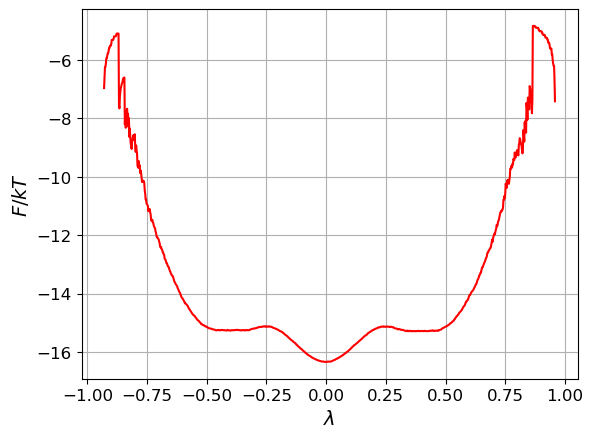

In [6]:
fig, ax = plt.subplots(1, 1)
plots.plot_fep(ax, cp.asarray(lam), xlabel='$\\lambda$')
plt.show()

## 4. Trajectory Indices

Single trajectory (`i_traj = 1` for all frames).

In [7]:
i_traj = np.ones_like(lam)          # trajectory index (1 = single trajectory)
t_traj = np.arange(len(lam))        # frame index

## 5. Train Committor (Non-Parametric), Several Seeds

`CommittorNE` rather than the equilibrium `Committor`: time reversal flips the velocity, so the reversible estimator does not apply to q(λ, v). The CVs are λ and the recorded velocity v; each iteration draws one of them.

The fit is repeated for every seed in `SEEDS` (the seed sets which CV and envelope centre each iteration draws). Each fit runs in chunks of `CHUNK` iterations; after every chunk the metrics, FEPs + Z_q and observed-vs-predicted plots and the (λ, v) map are shown here and saved to `figures/langevin_seeds/seed<s>/it<N>_*.png`, and the error against the brute-force reference q(x, v) is printed.

**Warm-up (optional):** the first `WARMUP_ITER` iterations of every seed can use their own envelope (`WARMUP_ENVELOPE`), gamma (`WARMUP_GAMMA`) and CV choice (`WARMUP_CV`: `None` random, `0` λ only, `1` v only); then `ENVELOPE` and `GAMMA` take over. The seed matters through the first CVs drawn: in a test with seeds 0–3, the one run that drew v first (seed 1) reached the exact committor (RMS 0.019) and the three that drew λ first kept sharp edges at λ ≈ ±0.29 (RMS 0.052 for seed 0). `WARMUP_CV = 1` with a short warm-up tests this. `fit_transform` continues from the current RC on every call, so the chunks form one continuous run.

`lazy_basis=True` evaluates the basis in fused GPU kernels: about 4× faster here, same result. It is used instead of fewer frames: the statistical error of the comparison grows from 0.012 per bin at 6M frames to 0.020 at 2M.

**Parameters:**
| Parameter | Value | Description |
|-----------|-------|-------------|
| `SEEDS` | 0, 1 | Random seeds |
| `MAX_ITER` | 15000 | Iterations per seed after the warm-up |
| `CHUNK` | 5000 | Iterations between shown and saved plots |
| `ENVELOPE` | 1 | RC envelope width (`envelope_scale`) |
| `GAMMA` | 0.1 | Regularization (scales the step; does not change the fixed point) |
| `WARMUP_ITER` | 0 | Warm-up iterations (0 = off) |
| `WARMUP_ENVELOPE`, `WARMUP_GAMMA`, `WARMUP_CV` | 1, 0.1, None | Warm-up settings |
| `ny` | 6 | Polynomial degree |

#=1000, xent=0.445313, mse=0.156779, sdzq=1226.9, dzq=2837.27, dr2=13680.1, auc=0.844971, |dx|=0.160315, time=38.4151


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3329223/330590838.py:37: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)


--- figures/langevin_seeds_dt5e-4/seed4, warmup1000 ---


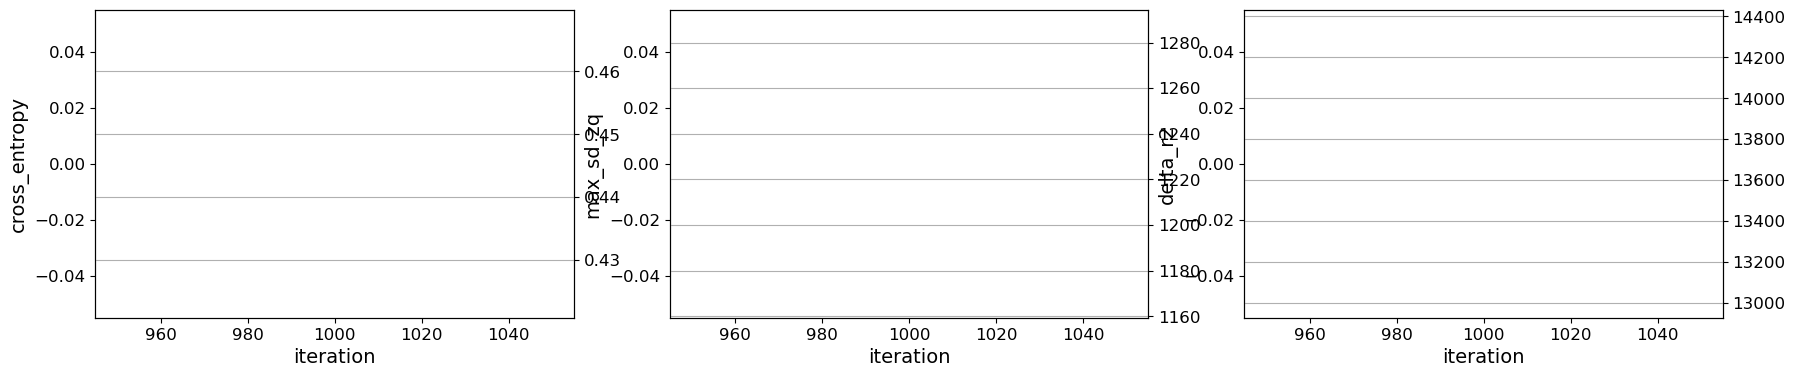

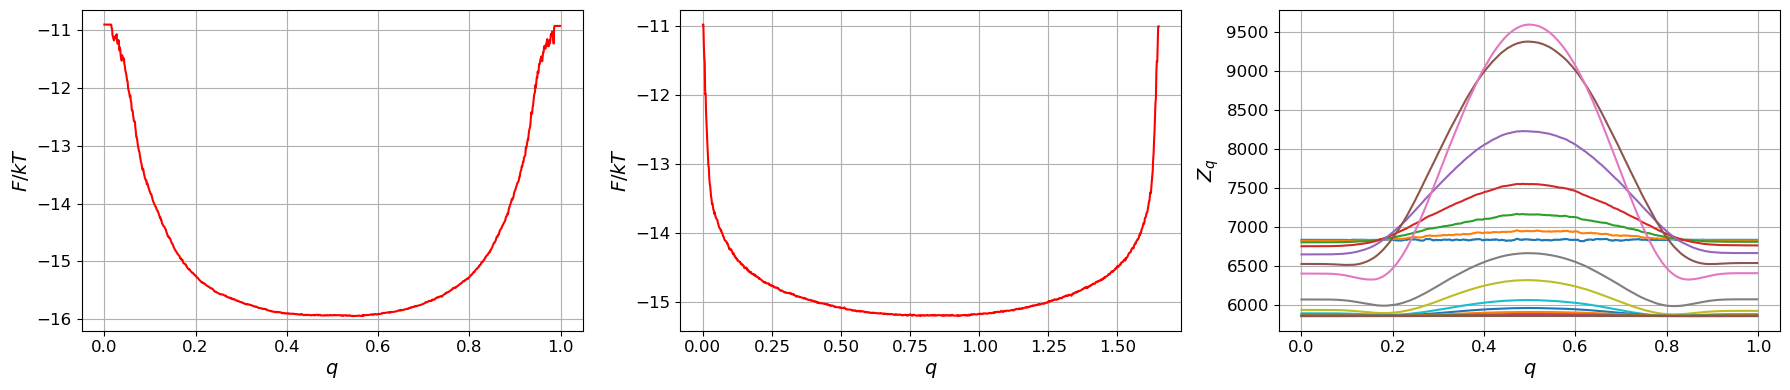

/local/data/data-fbsskr/conda_envs/RL/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


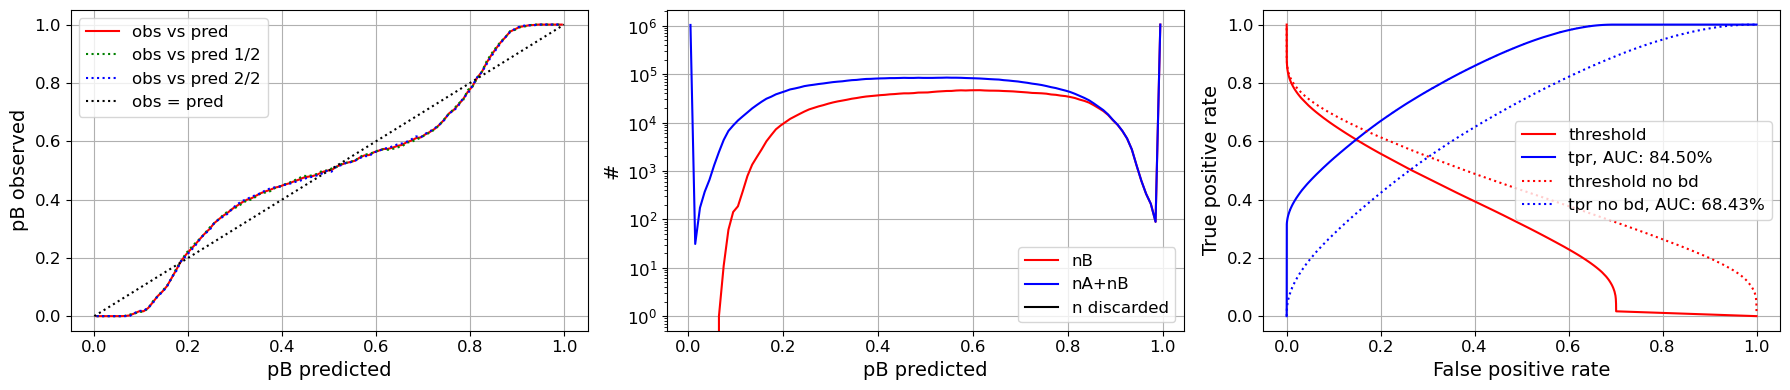

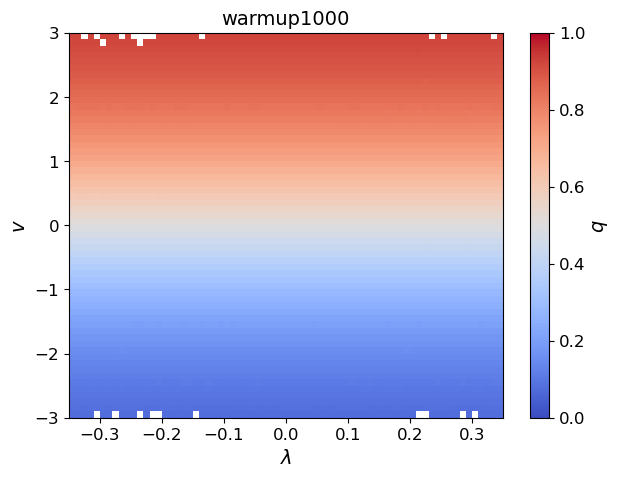

seed 4, warm-up 1000 iterations: RMS(fit - exact) per frame 0.1554
#=2000, xent=0.398037, mse=0.139573, sdzq=27.4975, dzq=94.3084, dr2=11391.1, auc=0.871541, |dx|=0.134576, time=47.0256
#=3000, xent=0.398014, mse=0.139565, sdzq=30.688, dzq=86.192, dr2=11396.2, auc=0.871567, |dx|=0.0015758, time=89.5549
#=4000, xent=0.397993, mse=0.139562, sdzq=31.0906, dzq=89.6546, dr2=11400.9, auc=0.871578, |dx|=0.000751103, time=132.131
#=5000, xent=0.397985, mse=0.139557, sdzq=31.0118, dzq=85.8462, dr2=11404.9, auc=0.871587, |dx|=0.000555099, time=178.863
#=6000, xent=0.397983, mse=0.139558, sdzq=30.8127, dzq=86.3698, dr2=11405.9, auc=0.87158, |dx|=0.000446631, time=222.62


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:390: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/tmp/ipykernel_3329223/330590838.py:37: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)


--- figures/langevin_seeds_dt5e-4/seed4, it6000 ---


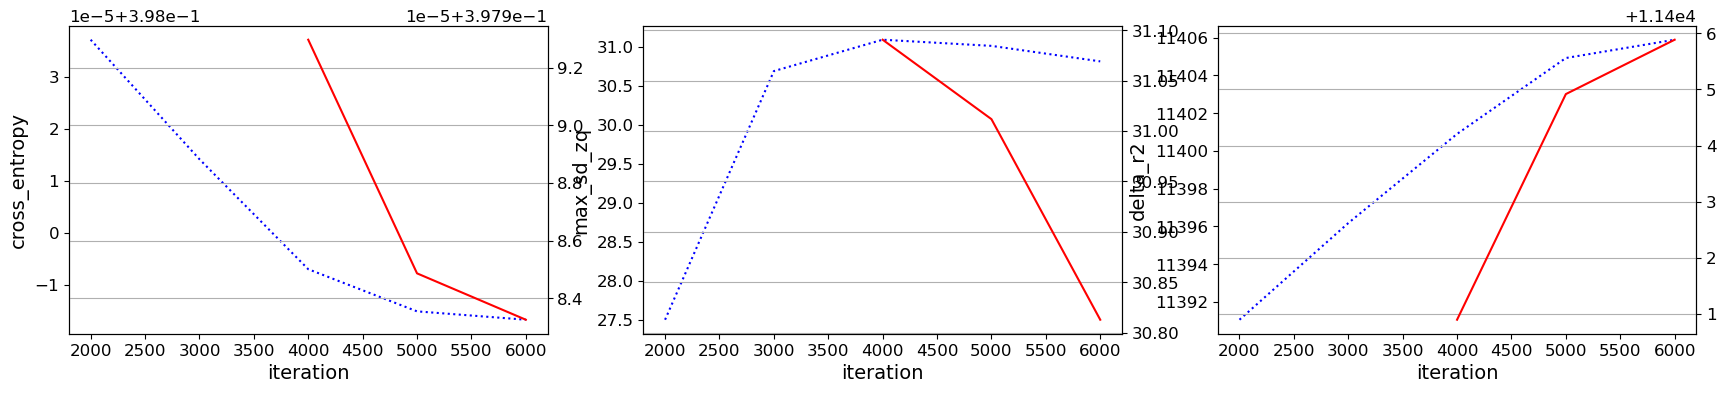

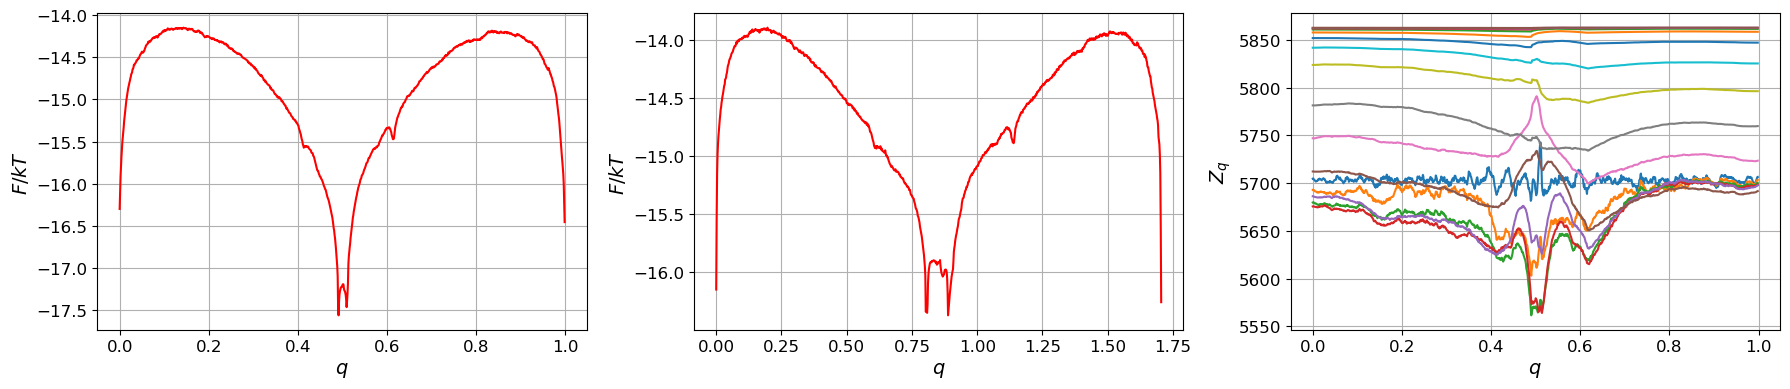

/local/data/data-fbsskr/conda_envs/RL/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


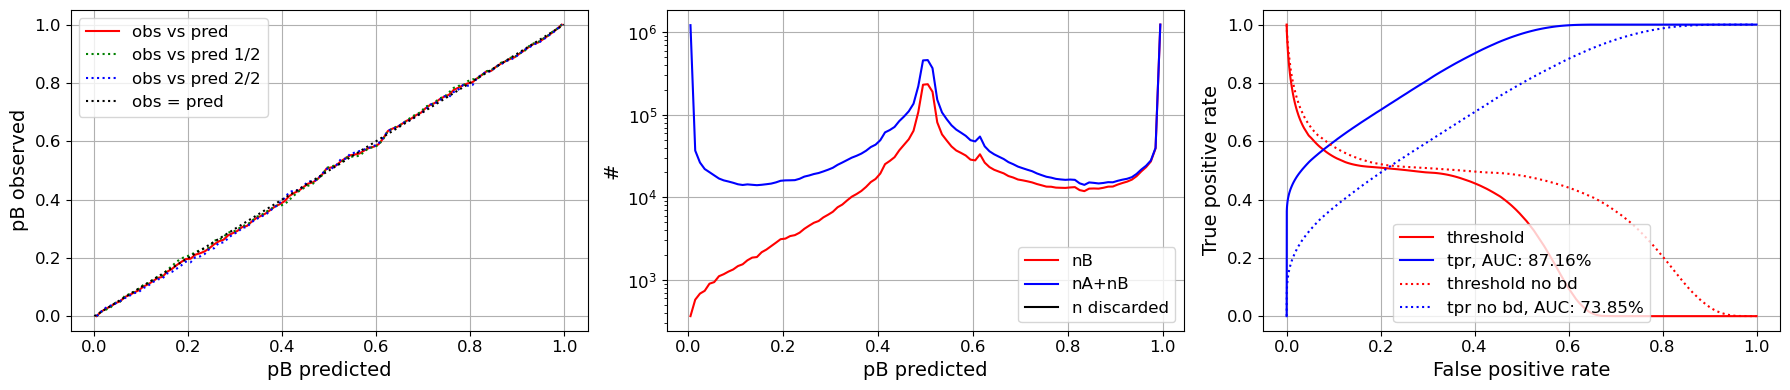

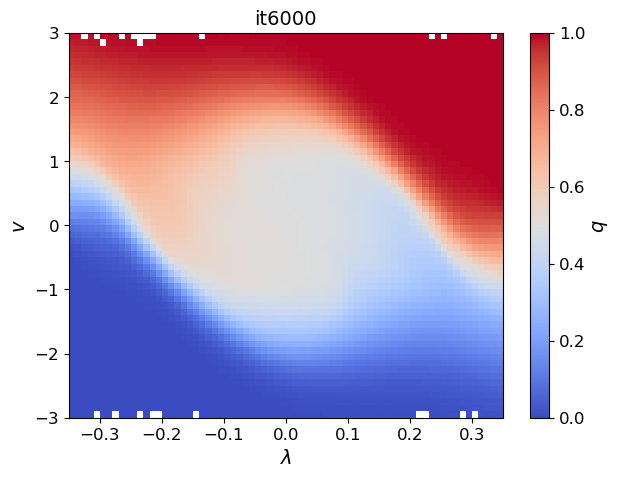

seed 4, 6000 iterations: RMS(fit - exact) per frame 0.0204, plots in figures/langevin_seeds_dt5e-4/seed4


In [ ]:
import os
from scipy.interpolate import RegularGridInterpolator

SEEDS = [4, 5, 6]
MAX_ITER = 15000
CHUNK = 5000
OUT = 'figures/langevin_seeds_dt5e-4'

ENVELOPE = 0.01                       # envelope_scale for the main run
GAMMA = 0.1                        # regularization strength for the main run
# Optional warm-up: the first WARMUP_ITER iterations of every seed use their own envelope, gamma
# and CV choice, then the main settings take over. WARMUP_ITER = 0 switches it off.
WARMUP_ITER = 1000
WARMUP_ENVELOPE = 1
WARMUP_GAMMA = 0.1
WARMUP_CV = 1                   # None: random CV as in the main run; 0: lambda only; 1: v only
Y = cp.asarray(np.c_[lam, v])      # CVs: lambda and the recorded velocity

# brute-force reference q(x, v), for the progress printout
ref = np.load('figures/well_check/reference.npz')
f_ref = RegularGridInterpolator((ref['xs'], ref['vs']), ref['q'], bounds_error=False, fill_value=None)
q_exact = np.clip(f_ref(np.c_[np.clip(lam, ref['xs'][0], ref['xs'][-1]), np.clip(v, ref['vs'][0], ref['vs'][-1])]), 0, 1)
free = (lam > lambda_a) & (lam < lambda_b)
edges_l, edges_v = np.linspace(lambda_a, lambda_b, 71), np.linspace(-3, 3, 61)
n_lv = np.histogram2d(lam, v, [edges_l, edges_v])[0]

def save_plots(q, folder, tag):
    # the library's plot methods call plt.show(); hold it off so every figure can be saved,
    # then show them all inline at the end
    show, plt.show = plt.show, (lambda *a, **k: None)
    try:
        q.plots_metrics(['cross_entropy', 'max_sd_zq', 'delta_r2'])
        plt.gcf().savefig(f'{folder}/{tag}_metrics.png', dpi=100)
        q.plots_feps(delta_t_sim=dt)
        plt.gcf().savefig(f'{folder}/{tag}_feps.png', dpi=100)
        q.plots_obs_pred()
        plt.gcf().savefig(f'{folder}/{tag}_obs_pred.png', dpi=100)
        r = cp.asnumpy(q.r_traj)
        s = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)[0]
        fig, ax = plt.subplots(figsize=(7, 5))
        im = ax.pcolormesh(edges_l, edges_v, np.where(n_lv > 20, s / np.maximum(n_lv, 1), np.nan).T,
                           cmap='coolwarm', vmin=0, vmax=1)
        fig.colorbar(im, ax=ax, label='$q$'); ax.set(xlabel='$\\lambda$', ylabel='$v$', title=tag)
        fig.savefig(f'{folder}/{tag}_q_lambda_v.png', dpi=100)
    finally:
        plt.show = show
    print(f'--- {folder}, {tag} ---')
    plt.show()                     # display (and close) the four figures
    return r

results = {}
for seed in SEEDS:
    folder = f'{OUT}/seed{seed}'
    os.makedirs(folder, exist_ok=True)
    np.random.seed(seed); cp.random.seed(seed)
    q = optimalrcs.CommittorNE(
        boundary0=lam <= lambda_a,     # state A
        boundary1=lam >= lambda_b,     # state B
        i_traj=i_traj,
        t_traj=t_traj,
    )
    if WARMUP_ITER > 0:
        optimalrcs.envelope_scale = WARMUP_ENVELOPE
        comp_y = (lambda: Y[:, np.random.randint(2)]) if WARMUP_CV is None else (lambda: Y[:, WARMUP_CV])
        q.fit_transform(comp_y, gamma=WARMUP_GAMMA, ny=6, max_iter=WARMUP_ITER, print_step=WARMUP_ITER,
                        save_min_delta_zq=False, lazy_basis=True)
        r = save_plots(q, folder, f'warmup{WARMUP_ITER}')
        print(f'seed {seed}, warm-up {WARMUP_ITER} iterations: RMS(fit - exact) per frame '
              f'{np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}', flush=True)
    optimalrcs.envelope_scale = ENVELOPE
    for done in range(CHUNK, MAX_ITER + 1, CHUNK):
        q.fit_transform(
            lambda: Y[:, np.random.randint(2)],
            gamma=GAMMA,
            ny=6,
            max_iter=CHUNK,
            print_step=1000,
            save_min_delta_zq=False,
            lazy_basis=True,
        )
        r = save_plots(q, folder, f'it{WARMUP_ITER + done}')
        rms = np.sqrt(np.mean((r[free] - q_exact[free]) ** 2))
        print(f'seed {seed}, {WARMUP_ITER + done} iterations: RMS(fit - exact) per frame {rms:.4f}, plots in {folder}', flush=True)
    np.save(f'{folder}/q_traj.npy', r.astype(np.float32))
    results[seed] = r

# Final RMS per seed (the plots of every chunk are shown above)
for seed, r in results.items():
    print(f'seed {seed}: RMS(fit - exact) per frame {np.sqrt(np.mean((r[free] - q_exact[free]) ** 2)):.4f}')

## 6. Committor in the (λ, v) Plane

Mean q per (λ, v) bin, using the true velocity from the MD. If the history captured the velocity, q depends on v and not only on λ: particles moving towards B have higher q.

In [ ]:
r = cp.asnumpy(q.r_traj)
edges_l = np.linspace(lambda_a, lambda_b, 71)
edges_v = np.linspace(-3, 3, 61)
n, _, _ = np.histogram2d(lam, v, [edges_l, edges_v])
s, _, _ = np.histogram2d(lam, v, [edges_l, edges_v], weights=r)
q_lv = np.where(n > 20, s / np.maximum(n, 1), np.nan)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
im = ax.pcolormesh(edges_l, edges_v, q_lv.T, cmap='coolwarm', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='$q$')
ax.set(xlabel='$\\lambda$', ylabel='$v$')
plt.show()

## 7. Save Results

Uncomment to save the raw committor trajectory to disk.

In [ ]:
np.save('figures/langevin_dt5e-4/q_traj_last_seed.npy', cp.asnumpy(q.r_traj).astype(np.float32))